In [1]:
# we need:
# Dataset:
#   continent distribution chart
#   a topic pie chart
#   tables

# Analysis:
#   a global country-level attitude shift map
#   a north america state/province-level attitude shift map


# for dataset visualization: https://sankeymatic.com/build/
# need to format the input data accordingly

In [2]:
import json
import pandas as pd

In [ ]:
# ### DO NOT RUN AGAIN AS THIS IS A ONE-TIME MANUAL FIX FOR SOME MINOR ANNOTATION ISSUES

# # add geo paths to topic-related subreddits
# topic_subreddits = json.load(open("../C-subreddit_selection/subreddits_topic_info.json", "r" ))

# # dictionary of subreddits info, e.g.
# #     "boxoffice": {
# #         "Geo_Estimate": "GLOBAL",
# #         "Topic": [
# #             [
# #                 "ENTERTAINMENT",
# #                 "BUSINESS/ECONOMICS/FINANCE"
# #             ]
# #         ]
# #     },

# # manually map Geo_Estimate to a path.

# Geo_Estimates = {info["Geo_Estimate"] for _, info in topic_subreddits.items()}
# print(Geo_Estimates)


# # Manual mapping
# geo_estimates_to_paths = {
#     'GLOBAL': "GLOBAL",
#     'USA/GLOBAL': "GLOBAL-NORTH AMERICA-USA",
#     'CAN': "GLOBAL-NORTH AMERICA-CAN",
#     'AUS': "GLOBAL-OCEANIA-AUS",
#     'USA': "GLOBAL-NORTH AMERICA-USA",
#     'GBR': "GLOBAL-EUROPE-GBR",
#     'NORTH AMERICA': "GLOBAL-NORTH AMERICA"
# }

# # reformat topic subreddits

# subreddits_reformatted = {}
# for subreddit, info in topic_subreddits.items():
#     subreddits_reformatted[subreddit] = {
#         "geopath": geo_estimates_to_paths[info["Geo_Estimate"]],
#         "topics": info["Topic"][0]
#     }

# # show all topics
# all_topics = set()
# for info in subreddits_reformatted.values():
#     for topic in info["topics"]:
#         all_topics.add(topic)
# print(all_topics)

# # add topic info to subreddit_geo_info.json (generic or covid-related)
# geo_subreddits = json.load(open("../C-subreddit_selection/subreddit_geo_info.json", "r" ))

# subreddit_to_geo_paths = geo_subreddits["subreddit_to_geo_paths"]
# subreddit_is_covid_specific = geo_subreddits["subreddit_is_covid_specific"]


# for subreddit, geo_paths in subreddit_to_geo_paths.items():
#     if len(geo_paths) > 1:
#         assert subreddit in ["CoronavirusUS", "CoronavirusDownunder"]
#         continue # handled manually
#     geopath = geo_paths[0]
#     is_covid_specific = subreddit_is_covid_specific[subreddit]
#     topics = ["COVID"] if is_covid_specific else ["Comprehensive"]
#     subreddits_reformatted[subreddit] = {
#         "geopath": geopath,
#         "topics": topics
#     }

# # weedstocks's topic missing FINANCE
# # print(subreddits_reformatted["weedstocks"]["topics"]) => ['SOCIAL_DISCUSSION_AND_THOUGHTS', 'HEALTH', 'BUSINESS/ECONOMICS']

# weedstocks_topics_should_be = ['SOCIAL_DISCUSSION_AND_THOUGHTS', 'HEALTH', 'BUSINESS/ECONOMICS/FINANCE']

# subreddits_reformatted["weedstocks"]["topics"] = weedstocks_topics_should_be

# # manually handle multi-geopath subreddits
# subreddits_reformatted["CoronavirusUS"] = {
#     "geopath": "GLOBAL-NORTH AMERICA-USA+CAN",
#     "topics": ["COVID"]
# }

# subreddits_reformatted["CoronavirusDownunder"] = {
#     "geopath": "GLOBAL-OCEANIA-AUS+NZL",
#     "topics": ["COVID"]
# }

# # path error: 
# # print(subreddits_reformatted["CoronavirusUK"]) # GLOBAL-NORTH AMERICA-GBR-EUROPE-CoronavirusUK 
# CoronavirusUK_geopath_should_be = "GLOBAL-EUROPE-GBR"
# subreddits_reformatted["CoronavirusUK"]["geopath"] = CoronavirusUK_geopath_should_be

# # save the reformatted subreddit geo and topic info
# with open("subreddits_geo_topic_info.json", "w") as f:
#     json.dump(subreddits_reformatted, f, indent=4)

{'RELIGION', 'BUSINESS/ECONOMICS/FINANCE', 'HEALTH', 'TECHNOLOGY', 'SCIENCE', 'BUSINESS/ECONOMICS', 'COVID', 'SPORTS', 'POLITICS', 'SOCIAL_DISCUSSION_AND_THOUGHTS', 'ENTERTAINMENT'}


In [ ]:
subreddits_reformatted = json.load(open("subreddits_geo_topic_info.json", "r" ))

In [ ]:
# # prep for drawing

# # topic counts
# topic_counts = {}
# for info in subreddits_reformatted.values():
#     for topic in info["topics"]:
#         if topic not in topic_counts:
#             topic_counts[topic] = 0
#         topic_counts[topic] += 1

# # pretty print
# for topic, count in topic_counts.items():
#     print(f"{topic}: {count}")

SOCIAL_DISCUSSION_AND_THOUGHTS: 29
TECHNOLOGY: 4
RELIGION: 2
BUSINESS/ECONOMICS/FINANCE: 7
POLITICS: 26
SPORTS: 8
ENTERTAINMENT: 7
COVID: 34
HEALTH: 5
SCIENCE: 5
Comprehensive: 94


In [ ]:
# # for each topic, count their corresponding geopaths
# topic_geopath_counts = {}
# for subreddit,info in subreddits_reformatted.items():
#     geopath = info["geopath"]
#     path_nodes = geopath.split('-')
#     sub_paths = []
#     for i in range(1, len(path_nodes)+1):
#         sub_path = '-'.join(path_nodes[:i])
#         sub_paths.append(sub_path)
#     # print(f"{subreddit}: {sub_paths}")
#     for topic in info["topics"]:
#         for sub_path in sub_paths:
#             if topic not in topic_geopath_counts:
#                 topic_geopath_counts[topic] = {}
#             if sub_path not in topic_geopath_counts[topic]:
#                 topic_geopath_counts[topic][sub_path] = 0
#             topic_geopath_counts[topic][sub_path] += 1

# # pretty print
# print('-------------------------')
# for topic, geopath_counts in topic_geopath_counts.items():
#     print(f"{topic}: {topic_counts[topic]}")
#     # show paths up to 4 nodes
#     # sort alphabetically
#     for geopath, count in sorted(geopath_counts.items()):
#         if len(geopath.split('-')) <= 4:
#             print(f"  {geopath}: {count}")
#     print('-------------------------')

-------------------------
SOCIAL_DISCUSSION_AND_THOUGHTS: 29
  GLOBAL: 29
  GLOBAL-NORTH AMERICA: 7
  GLOBAL-NORTH AMERICA-CAN: 1
  GLOBAL-NORTH AMERICA-USA: 6
-------------------------
TECHNOLOGY: 4
  GLOBAL: 4
-------------------------
RELIGION: 2
  GLOBAL: 2
-------------------------
BUSINESS/ECONOMICS/FINANCE: 7
  GLOBAL: 7
  GLOBAL-OCEANIA: 1
  GLOBAL-OCEANIA-AUS: 1
-------------------------
POLITICS: 26
  GLOBAL: 26
  GLOBAL-EUROPE: 4
  GLOBAL-EUROPE-GBR: 4
  GLOBAL-NORTH AMERICA: 14
  GLOBAL-NORTH AMERICA-CAN: 1
  GLOBAL-NORTH AMERICA-USA: 13
  GLOBAL-OCEANIA: 1
  GLOBAL-OCEANIA-AUS: 1
-------------------------
SPORTS: 8
  GLOBAL: 8
  GLOBAL-NORTH AMERICA: 4
  GLOBAL-NORTH AMERICA-USA: 3
-------------------------
ENTERTAINMENT: 7
  GLOBAL: 7
  GLOBAL-NORTH AMERICA: 2
  GLOBAL-NORTH AMERICA-USA: 2
-------------------------
COVID: 34
  GLOBAL: 34
  GLOBAL-EUROPE: 2
  GLOBAL-EUROPE-GBR: 1
  GLOBAL-EUROPE-IRL: 1
  GLOBAL-NORTH AMERICA: 23
  GLOBAL-NORTH AMERICA-CAN: 2
  GLOBAL-NORTH

In [ ]:
# # show subreddits matching each exact path
# topic_to_geo_path_to_subreddits = {}
# for subreddit, info in subreddits_reformatted.items():
#     geopath = info["geopath"]
#     topics = info["topics"]
#     for topic in topics:
#         if topic not in topic_to_geo_path_to_subreddits:
#             topic_to_geo_path_to_subreddits[topic] = {}
#         if geopath not in topic_to_geo_path_to_subreddits[topic]:
#             topic_to_geo_path_to_subreddits[topic][geopath] = []
#         topic_to_geo_path_to_subreddits[topic][geopath].append(f"/r/{subreddit}")

# # pretty print

# for topic, geopath_counts in topic_geopath_counts.items():
#     print(f"{topic}: {topic_counts[topic]} subreddits")
#     for geopath, count in geopath_counts.items():
#         print(f"    {geopath}: {count} subreddits on route")
#         if geopath not in topic_to_geo_path_to_subreddits[topic]:
#             print("        No subreddits matching this exact path.")
#         else:
#             print(f"        {len(topic_to_geo_path_to_subreddits[topic][geopath])} subreddit(s) matching this exact path:")
#             for subreddit in topic_to_geo_path_to_subreddits[topic][geopath]:
#                 print(f"            {subreddit}")
#     print("\n")

SOCIAL_DISCUSSION_AND_THOUGHTS: 29 subreddits
    GLOBAL: 29 subreddits on route
        22 subreddit(s) matching this exact path:
            /r/AnythingGoesNews
            /r/asianamerican
            /r/aznidentity
            /r/collapse
            /r/conspiracy
            /r/environment
            /r/Foodforthought
            /r/Futurology
            /r/inthenews
            /r/kotakuinaction2
            /r/news
            /r/nottheonion
            /r/offbeat
            /r/psychology
            /r/Sino
            /r/skeptic
            /r/slatestarcodex
            /r/television
            /r/UpliftingNews
            /r/weedstocks
            /r/worldevents
            /r/worldnews
    GLOBAL-NORTH AMERICA: 7 subreddits on route
        No subreddits matching this exact path.
    GLOBAL-NORTH AMERICA-USA: 6 subreddits on route
        6 subreddit(s) matching this exact path:
            /r/esist
            /r/JoeRogan
            /r/LeopardsAteMyFace
            /r/

In [ ]:
# # Country-level Sankey diagrams for topic -> geopaths visualization
# # Simply paste the following into https://sankeymatic.com/build/

# Business / Economics / Finance [1] AUS 
# AUS [1] Oceania
# Oceania [1] Global

# Business / Economics / Finance [6] Global

  
# Covid [1] GBR
# Covid [1] IRL
# GBR [1] Europe
# IRL [1] Europe
# Europe [2] Global

# Covid [20.5] USA
# Covid [2.5] CAN
# USA [20.5] North America
# CAN [2.5] North America
# North America [23] Global

# Covid [0.5] AUS
# Covid [0.5] NZL
# AUS [0.5] Oceania
# NZL [0.5] Oceania
# Oceania [1] Global

# Covid [8] Global

# Entertainment [2] USA
# USA [2] North America
# North America [2] Global

# Entertainment [5] Global



# Geographical-based (Comprehensive) [1] CHN
# CHN [1] Asia
# Geographical-based (Comprehensive) [3] IND
# IND [3] Asia
# Geographical-based (Comprehensive) [1] JPN
# JPN [1] Asia
# Geographical-based (Comprehensive) [1] KOR
# KOR [1] Asia
# Geographical-based (Comprehensive) [1] PHL
# PHL [1] Asia
# Geographical-based (Comprehensive) [1] SGP
# SGP [1] Asia
# Asia [8] Global

# Geographical-based (Comprehensive) [4] GBR
# GBR [4] Europe
# Geographical-based (Comprehensive) [1] IRL
# IRL [1] Europe
# Geographical-based (Comprehensive) [1] Europe
# Europe [6] Global

# Geographical-based (Comprehensive) [4] AUS
# AUS [4] Oceania
# Geographical-based (Comprehensive) [1] NZL
# NZL [1] Oceania
# Oceania [5] Global

# Geographical-based (Comprehensive) [17] CAN
# CAN [17] North America
# Geographical-based (Comprehensive) [58] USA
# USA [58] North America
# North America [75] Global 


# Health [5] Global



# Politics [4] GBR
# GBR [4] Europe
# Europe [4] Global

# Politics [1] CAN
# CAN [1] North America
# Politics [13] USA
# USA [13] North America
# North America [14] Global 

# Politics [1] AUS
# AUS [1] Oceania
# Oceania [1] Global

# Politics [7] Global



# Religion [2]  Global


# Science [5]  Global


# Social Discussion / Thoughts [1]
# CAN [1] North America
# Social Discussion / Thoughts [6] USA
# USA [6] North America
# North America [7] Global 

# Social Discussion / Thoughts [22] Global


# Sports [3] USA
# USA [3] North America
# Sports [1] North America
# North America [4] Global 

# Sports [4] Global

# Technology [4]  Global

In [1]:
## Now statistics.. (and a full recap of our data procedure... see written notes)
import json
import pandas as pd

# Table 1: counts of subreddits, posts, unique articles, reactions collected via A+B (raw data filtering), sampled via C (subreddit selection), & finally via D ().

# First row statistics
processed_raw = json.load(open("../C-subreddit_selection/all_in_one_english.json"))
# e.g. {
#     "worldnews": {
#         "2020-01": [
#             {
#                 "submission_id": "em49fj",
#                 "submission_date": "2020-01-08",
#                 "news_title": "China confirms new coronavirus as it investigates mystery Wuhan illness: New strain from the family that caused Sars is identified in 15 patients; 59 people reported as having been infected by outbreak traced to Wuhan seafood market",
#                 "news_content": "Chinese scientists say the new virus has been identified but more work is needed to fully understand it. Photo: Handout",
#                 "news_keywords": [
#                     "photo",
#                     "handout",
#                     "new virus",
#                     "chinese scientists"
#                 ],
#                 "reactions": [
#                     "Plague inc DLC?",
#                     "Now we have Fish Flu too??",
#                     "I've seen World War Z... Glad they have identified it and (hopefully) nullified the threat.",
#                     "Why are we allowing the family that caused Sars to create even more viruses?! Someone stop these maniacs!",
#                     "Given I'm experiencing some flu-like symptoms after eating fish, and at a market in Taipei this article is kind of worrying."
#                 ]
#             },
#            ...

posts = set() # submission ids
unique_articles = set() # by article title + content (same title but different content = different article)
subreddits = set() # subreddit names, without /r/
keyphrases = set() # all keyphrases across articles

reaction_count = 0 # no repetition thus no need to store
reaction_word_len_count = 0

for subreddit, monthly_data in processed_raw.items():
    subreddits.add(subreddit)
    for month, month_list in monthly_data.items():
        for entry in month_list:
            posts.add(entry["submission_id"])
            unique_articles.add("{title}: {content}".format(title=entry["news_title"], content=entry["news_content"]))
            keyphrases.update(entry["news_keywords"])
            for reaction in entry["reactions"]:
                if reaction.strip() != "":
                    reaction_count += 1
                    reaction_word_len_count += len(reaction.split())

print(f"# Subreddits:     {len(subreddits)}")
print(f"# Articles:       {len(unique_articles)}")
print(f"# Keyphrases:     {len(keyphrases)}")
print(f"# Posts:          {len(posts)}")
print(f"# Reactions:      {reaction_count}")
print(f"Avg reaction len: {reaction_word_len_count / reaction_count:.2f}")



# Subreddits:     4206
# Articles:       117747
# Keyphrases:     199399
# Posts:          141487
# Reactions:      651433
Avg reaction len: 40.35


In [2]:
# after community selection
# "worldnews": {
#         "subreddit_info": {
#             "type": "topic",
#             "info": {
#                 "Geo_Estimate": "GLOBAL",
#                 "Topic": [
#                     [
#                         "SOCIAL_DISCUSSION_AND_THOUGHTS"
#                     ]
#                 ]
#             }
#         },
#         "monthly_record": {
#             "2020-01": [
#                 {
#                     "submission_id": "em49fj",
#                     "submission_date": "2020-01-08",
#                     "news_title": "China confirms new coronavirus as it investigates mystery Wuhan illness: New strain from the family that caused Sars is identified in 15 patients; 59 people reported as having been infected by outbreak traced to Wuhan seafood market",
#                     "news_content": "Chinese scientists say the new virus has been identified but more work is needed to fully understand it. Photo: Handout",
#                     "news_keywords": [
#                         "photo",
#                         "handout",
#                         "new virus",
#                         "chinese scientists"
#                     ],
#                     "reactions": [
#                         "Plague inc DLC?",
#                         "Now we have Fish Flu too??",
#                         "I've seen World War Z... Glad they have identified it and (hopefully) nullified the threat.",
#                         "Why are we allowing the family that caused Sars to create even more viruses?! Someone stop these maniacs!",
#                         "Given I'm experiencing some flu-like symptoms after eating fish, and at a market in Taipei this article is kind of worrying."
#                     ]
#                 },

comm_selected = json.load(open("../C-subreddit_selection/comm_data.json"))

posts = set() # submission ids
unique_articles = set() # by article title + content (same title but different content = different article)
subreddits = set() # subreddit names, without /r/
keyphrases = set() # all keyphrases across articles

reaction_count = 0 # no repetition thus no need to store
reaction_word_len_count = 0

for subreddit, data in comm_selected.items():
    subreddits.add(subreddit)
    monthly_data = data["monthly_record"]
    for month, month_list in monthly_data.items():
        for entry in month_list:
            posts.add(entry["submission_id"])
            unique_articles.add("{title}: {content}".format(title=entry["news_title"], content=entry["news_content"]))
            keyphrases.update(entry["news_keywords"])
            for reaction in entry["reactions"]:
                if reaction.strip() != "":
                    reaction_count += 1
                    reaction_word_len_count += len(reaction.split())

print(f"After community selection:")
print(f"# Subreddits:     {len(subreddits)}")
print(f"# Articles:       {len(unique_articles)}")
print(f"# Keyphrases:     {len(keyphrases)}")
print(f"# Posts:          {len(posts)}")
print(f"# Reactions:      {reaction_count}")
print(f"Avg reaction len: {reaction_word_len_count / reaction_count:.2f}")

After community selection:
# Subreddits:     207
# Articles:       99531
# Keyphrases:     170055
# Posts:          117478
# Reactions:      546357
Avg reaction len: 40.68


In [3]:
# article sampling via keyphrase selection

data = json.load(open('../D-keyword_selection/comm_reactions.json'))

keyw_2_subm_ids = data["keyw_2_subm_ids"]
subr_2_monthly_subm_ids = data["subr_2_monthly_subm_ids"]
subm_id_2_entry = data["subm_id_2_entry"]

subreddits = subr_2_monthly_subm_ids.keys() # subreddit names, without /r/
selected_keyphrases = keyw_2_subm_ids.keys() # all keyphrases across articles
posts = subm_id_2_entry.keys() # submission ids

unique_articles = set() # by article title + content (same title but different content = different article)
remaining_keyphrases = set() # all keyphrases across articles after sampling (not the selected keyphrases, but all keyphrases that appear in the remaining articles after sampling)
reaction_count = 0 # no repetition thus no need to store
reaction_word_len_count = 0

# "subm_id_2_entry": {
#     "em49fj": {
#         "subreddit": "worldnews",
#         "submission_date": "2020-01-08",
#         "news_title": "China confirms new coronavirus as it investigates mystery Wuhan illness: New strain from the family that caused Sars is identified in 15 patients; 59 people reported as having been infected by outbreak traced to Wuhan seafood market",
#         "news_content": "Chinese scientists say the new virus has been identified but more work is needed to fully understand it. Photo: Handout",
#         "selected_keywords": [
#             "new virus"
#         ],
#         "all_keywords": [
#             "photo",
#             "handout",
#             "new virus",
#             "chinese scientists"
#         ],
#         "reactions": [
#             "Plague inc DLC?",
#             "Now we have Fish Flu too??",
#             "I've seen World War Z... Glad they have identified it and (hopefully) nullified the threat.",
#             "Why are we allowing the family that caused Sars to create even more viruses?! Someone stop these maniacs!",
#             "Given I'm experiencing some flu-like symptoms after eating fish, and at a market in Taipei this article is kind of worrying."
#         ]
#     },

for subm_id, entry in subm_id_2_entry.items():
    unique_articles.add("{title}: {content}".format(title=entry["news_title"], content=entry["news_content"]))
    remaining_keyphrases.update(entry["all_keywords"])
    for reaction in entry["reactions"]:
        if reaction.strip() != "":
            reaction_count += 1
            reaction_word_len_count += len(reaction.split())

print(f"After article sampling via keyphrase selection:")
print(f"# Subreddits:     {len(subreddits)}")
print(f"# Articles:       {len(unique_articles)}")
print(f"# Keyphrases:     {len(remaining_keyphrases)}")
print(f"# Posts:          {len(posts)}")
print(f"# Reactions:      {reaction_count}")
print(f"Avg reaction len: {reaction_word_len_count / reaction_count:.2f}")

After article sampling via keyphrase selection:
# Subreddits:     207
# Articles:       57019
# Keyphrases:     94431
# Posts:          67654
# Reactions:      315977
Avg reaction len: 40.03


In [ ]:
# # older scripts and data, no longer used

# # read jsonl

# with open("../../reaction_tone_to_attitude/batch_round/sampled_batch_data.jsonl") as f:
#     final_eval_data = [json.loads(line) for line in f]

# # example line:
# # {"subreddit": "britishcolumbia", "submission_date": "2020-11-24", "news_title": "2020-11-24 Tuesday BC Covid Update =&gt; 941 new cases (NEW DAILY RECORD) and 10 fatalities; 284 in hospital and 61 in ICU", "news_content": "Send this page to someone via email\nEditor\u2019s note: B.C. health officials incorrectly reported the number of new COVID-19 cases on Tues, Nov. 24 due to a technical error. The numbers below have since been corrected. For more COVID-19 data, go to the BC Centre for Disease Control website.\nB.C. reported another 695 new cases of COVID-19 on Tuesday and 10 new deaths.\nFraser Health saw 432 new cases of the disease, while Vancouver Coastal Health recorded 174.\nThe 10 deaths brought B.C.\u2019s COVID-19 death toll to 358.\n0:34 Coronavirus: B.C. orders all indoor group fitness activities to close immediately\nThe number of people in hospital rose by seven to 284, a new record. Of those, 61 are in intensive care, an increase of three from Monday when the province reported 1,933 new COVID-19 cases and 17 deaths over a span of three days.\nStory continues below advertisement\nThere are 7,732 active cases in the province and a total of 10,283 people are in self-isolation due to possible exposure to the coronavirus.\n[ Sign up for our Health IQ newsletter for the latest coronavirus updates ]\nEarlier in the day, the province ordered all gymnastic centres, dance studios, martial arts venues and yoga studios in British Columbia to close immediately while new guidance is being developed.\n1:52 Christmas events put \u2018on hold\u2019 by pandemic\nLast week, provincial health officer Dr. Bonnie Henry announced new orders, including a mandatory mask mandate in indoor public spaces, the extension of Lower Mainland restrictions on social gatherings and a suspension on in-person religious services.\nThe order put the brakes on holiday events such as the VanDusen Festival of Lights, the Stanley Park Bright Nights Christmas Train or The Magic of Christmas at Butchart Gardens in Victoria.\nStory continues below advertisement\nOn Nov. 12, Henry released modelling data that indicated British Columbia could see more than 1,000 new COVID-19 cases a day if people don\u2019t cut down on contacts.\n2:11 B.C. releases November 2020 coronavirus modelling data\nHealth officials in Alberta brought in tougher COVID-19 restrictions Tuesday that include limits on social gatherings and less face-to-face class time for students.\nAlberta Premier Jason Kenney said there are to be no indoor gatherings, but people who live alone can have up to two personal contacts.\nHe said students in Grades 7 through 12 will transition next week to at-home learning and the school holiday break will be extended from Dec. 18 to Jan. 11.\n\u2014 With files from Richard Zussman and The Canadian Press", "selected_keywords": ["new deaths", "new covid-19 cases", "new cases", "social gatherings"], "all_keywords": ["new covid-19 cases", "people", "new deaths", "days", "province", "number", "social gatherings", "coronavirus", "bc centre", "new cases"], "reactions": ["NEW DAILY RECORD\n\nBC's #covid19 update Nov 24\n\n\n941 New cases \n10 death -358 total\nHosp/ICU (277/59) 284/61 <= NEW RECORDS\nActive (7360) 7732\nIsolated (10200) 10283\n19605 Recovered \nVCH (7821)+174\nFH (17047)+678 (more than entire prov yesterday)\nInt (1304)+49\nIsland (494)+11\nNorth (650)+29\n\n#bcpoli  @NEWS1130\n\nBC's #covid19 update Nov 24 Look at the over the past weeks\n\n\n3X the new cases today over Nov 3\nMore new in FH today than in BC yesterday\n\n1/4 BC's covid deaths have been in last 3.5 weeks (that's a lot of people's parents, grandparents, siblings)\n\n\n\nmajor Burnaby hospital outbreak! 55 patients & 40 staff with Covid likely from fire last week; 5 fatal   \n\n\n[CBC case \n\n\n[News1130 historic \n\n\n[CKNW Health Authority \n\n\n\n\n\n[Indepth CBC \n\n\n[BCCDC COVID-19 Canadian and Global \n\n\nOutside of", "So I\u2019d say at this point the chances are very slim that restrictions get eased in time to allow extended family gatherings at Christmas, right?  \nIf so that will have a pretty significant impact in terms of stress, mental health etc. for a lot of people...", "We're in for a rough winter.  Sounds like vaccines are going to take a little longer than previously expected.\nWe should probably do more now to avoid catastrophe later.  It's only November.", "Schools are still chill though right? Restaurants and gyms too?\nCan we please just shut everything down so we don't have an enormous Christmas spike? Please?", "Every time I pop my head up to check the damage report from my home I\u2019ve been stuck in.\nThis year\u2019s seasonal depression gonna be a wild ride"], "submission_id": "k0h23z"}

# subreddits = set() # subreddit names, without /r/
# unique_articles = set() # by article title + content (same title but different content = different article)
# posts = set() # submission ids
# keyphrases = set() # all keyphrases across articles

# reaction_count = 0 # no repetition thus no need to store
# reaction_word_len_count = 0

# for entry in final_eval_data:
#     subreddits.add(entry["subreddit"])
#     posts.add(entry["submission_id"])
#     unique_articles.add("{title}: {content}".format(title=entry["news_title"], content=entry["news_content"]))
#     keyphrases.update(entry["all_keywords"])
#     for reaction in entry["reactions"]:
#         reaction_count += 1
#         reaction_word_len_count += len(reaction.split())

# print(f"After evaluation set sampling:")
# print(f"# Subreddits:     {len(subreddits)}")
# print(f"# Articles:       {len(unique_articles)}")
# print(f"# Keyphrases:     {len(keyphrases)}")
# print(f"# Posts:          {len(posts)}")
# print(f"# Reactions:      {reaction_count}")
# print(f"Avg reaction len: {reaction_word_len_count / reaction_count:.2f}")

After evaluation set sampling:
# Subreddits:     207
# Articles:       818
# Keyphrases:     3932
# Posts:          825
# Reactions:      3749
Avg reaction len: 42.31


In [4]:
# updating table 1 last-row:

import json
data = json.load(open('../D-keyword_selection/comm_reactions.json'))
keyw_2_subm_ids = data["keyw_2_subm_ids"]
subr_2_monthly_subm_ids = data["subr_2_monthly_subm_ids"]
subm_id_2_entry = data["subm_id_2_entry"]

subreddits = subr_2_monthly_subm_ids.keys() # subreddit names, without /r/
selected_keyphrases = keyw_2_subm_ids.keys() # all keyphrases across articles
posts = subm_id_2_entry.keys() # submission ids

unique_articles = set() # by article title + content (same title but different content = different article)
remaining_keyphrases = set() # all keyphrases across articles after sampling (not the selected keyphrases, but all keyphrases that appear in the remaining articles after sampling)
reaction_count = 0 # no repetition thus no need to store
reaction_word_len_count = 0

# "subm_id_2_entry": {
#     "em49fj": {
#         "subreddit": "worldnews",
#         "submission_date": "2020-01-08",
#         "news_title": "China confirms new coronavirus as it investigates mystery Wuhan illness: New strain from the family that caused Sars is identified in 15 patients; 59 people reported as having been infected by outbreak traced to Wuhan seafood market",
#         "news_content": "Chinese scientists say the new virus has been identified but more work is needed to fully understand it. Photo: Handout",
#         "selected_keywords": [
#             "new virus"
#         ],
#         "all_keywords": [
#             "photo",
#             "handout",
#             "new virus",
#             "chinese scientists"
#         ],
#         "reactions": [
#             "Plague inc DLC?",
#             "Now we have Fish Flu too??",
#             "I've seen World War Z... Glad they have identified it and (hopefully) nullified the threat.",
#             "Why are we allowing the family that caused Sars to create even more viruses?! Someone stop these maniacs!",
#             "Given I'm experiencing some flu-like symptoms after eating fish, and at a market in Taipei this article is kind of worrying."
#         ]
#     },
sampled_data = json.load(open("../../experiments/exp_data/all_sampled_ids.json"))
sampled_subm_ids = [sid for sub_dict in sampled_data.values() for sid in sub_dict.values()]
# sampled_subm_ids = 
for subm_id, entry in subm_id_2_entry.items():
    if subm_id in sampled_subm_ids:
        unique_articles.add("{title}: {content}".format(title=entry["news_title"], content=entry["news_content"]))
        remaining_keyphrases.update(entry["all_keywords"])
        for reaction in entry["reactions"]:
            if reaction.strip() != "":
                reaction_count += 1
                reaction_word_len_count += len(reaction.split())

print(f"After article sampling via keyphrase selection:")
print(f"# Subreddits:     {len(subreddits)}")
print(f"# Articles:       {len(unique_articles)}")
print(f"# Keyphrases:     {len(remaining_keyphrases)}")
print(f"# Posts:          {len(sampled_subm_ids)}")
print(f"# Reactions:      {reaction_count}")
print(f"Avg reaction len: {reaction_word_len_count / reaction_count:.2f}")

After article sampling via keyphrase selection:
# Subreddits:     207
# Articles:       2166
# Keyphrases:     8431
# Posts:          2194
# Reactions:      9947
Avg reaction len: 42.43


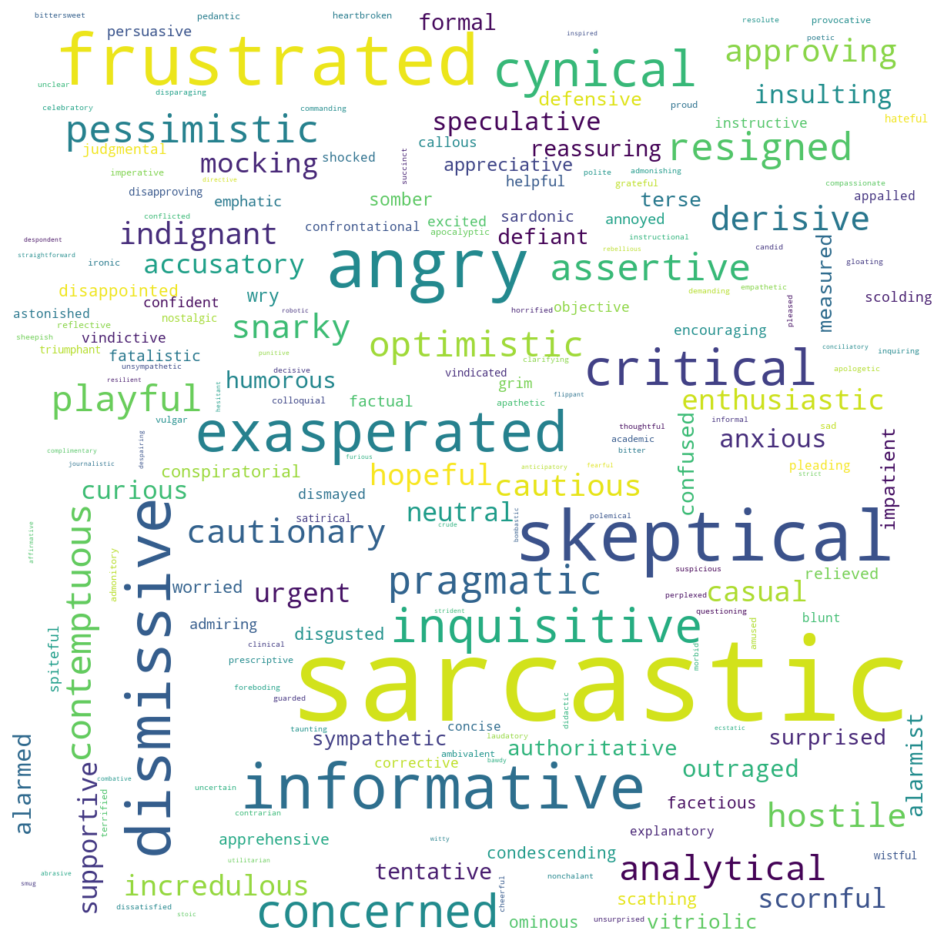

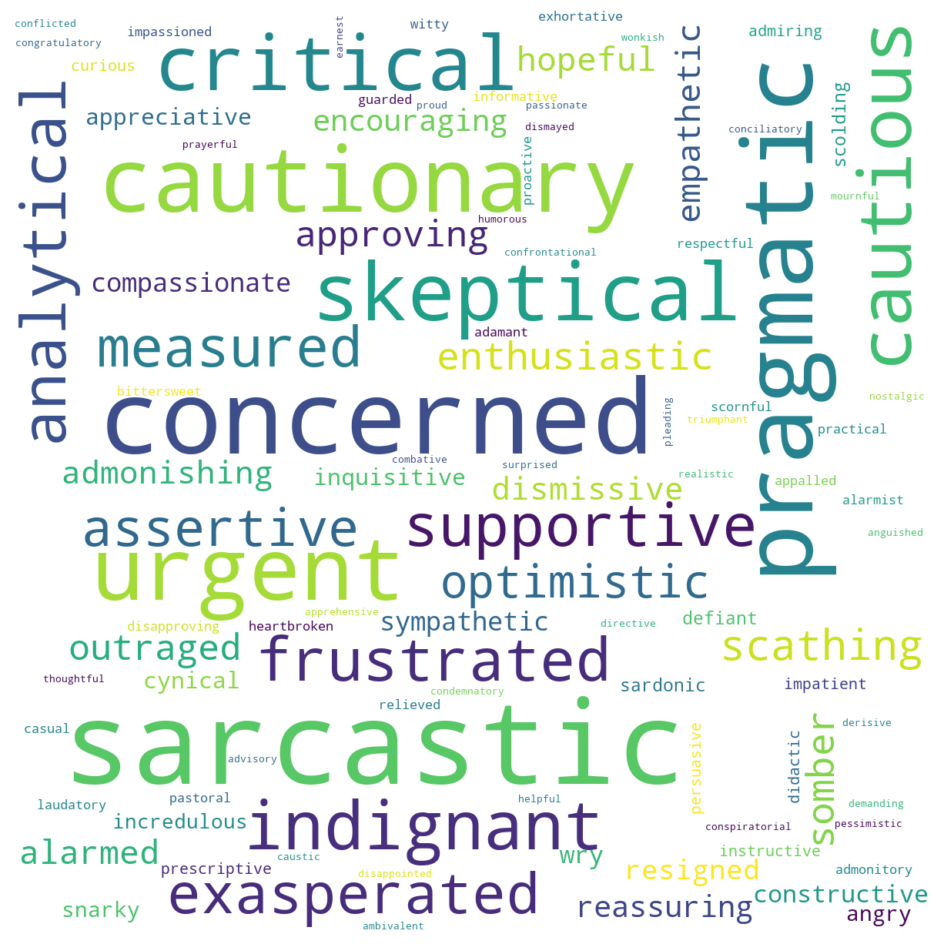

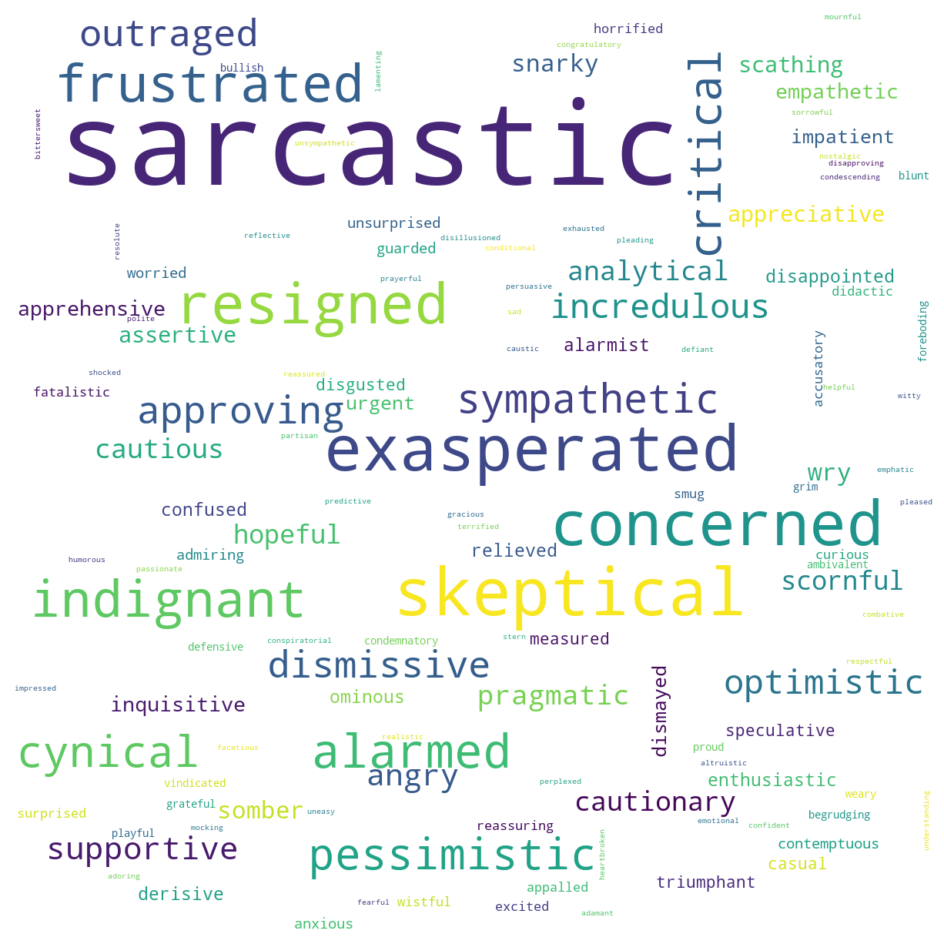

In [ ]:
# older scripts, not used anymore (replaced by tone freq rankings in the paper appendix)

# from wordcloud import WordCloud
# import matplotlib.pyplot as plt
# import json

# # read final data
# with open("final_data.json", "r") as f:
#     final_simulated_data = json.load(f)

# # dump all real tones to a text file for word cloud
# tones = []
# for subreddit, subreddit_dict in final_simulated_data.items():
#     for subm_id, subm_dict in subreddit_dict["submissions"].items():
#         for real_reaction in subm_dict["real_reactions"]:
#             tones.append(real_reaction["tone"])

# with open("real_tones.txt", "w") as f:
#     for tone in tones:
#         f.write(f"{tone}\n")

# # gemini simulated tones
# gemini_simulated_tones = []
# for subreddit, subreddit_dict in final_simulated_data.items():
#     for subm_id, subm_dict in subreddit_dict["submissions"].items():
#         for style in ["community-informed", "community-blind"]:
#             gemini_simulated_tones.append(subm_dict["simulated_reactions"]["Gemini-2.5-pro"][style]["tone"])
# with open("gemini_simulated_tones.txt", "w") as f:
#     for tone in gemini_simulated_tones:
#         f.write(f"{tone}\n")

# # gpt simulated tones
# gpt_simulated_tones = []
# for subreddit, subreddit_dict in final_simulated_data.items():
#     for subm_id, subm_dict in subreddit_dict["submissions"].items():
#         for style in ["community-informed", "community-blind"]:
#             gpt_simulated_tones.append(subm_dict["simulated_reactions"]["GPT-5"][style]["tone"])
            
# with open("gpt_simulated_tones.txt", "w") as f:
#     for tone in gpt_simulated_tones:
#         f.write(f"{tone}\n")

# # 1. Read the text file you just created
# with open("real_tones.txt", "r") as f:
#     text = f.read()

# # 2. Generate the word cloud
# # You can customize dimensions, background, and color palette (colormap)
# wordcloud = WordCloud(
#     width=1200, 
#     height=1200, 
#     background_color="white", 
#     colormap="viridis", # 'magma', 'plasma', or 'inferno' also look great on posters
#     collocations=False,     # <-- This forces unigrams only!
#     max_font_size=150,      # Keeps the top words from eating all the space
# ).generate(text)

# # 3. Plot the figure
# plt.figure(figsize=(12, 12))
# plt.imshow(wordcloud, interpolation="bilinear")
# plt.axis("off") # Hides the axes for a clean look

# # 4. Save the figure in high resolution (300 dpi is standard for print/posters)
# plt.savefig("tone_wordcloud.png", dpi=300, bbox_inches='tight')
# plt.show()

# # gpt simulated tones word cloud
# with open("gpt_simulated_tones.txt", "r") as f:
#     text = f.read()
# wordcloud = WordCloud(
#     width=1200, 
#     height=1200, 
#     background_color="white", 
#     colormap="viridis", # 'magma', 'plasma', or 'inferno' also look great on posters
#     collocations=False,     # <-- This forces unigrams only!
#     max_font_size=150,      # Keeps the top words from eating all the space
# ).generate(text)
# plt.figure(figsize=(12, 12))
# plt.imshow(wordcloud, interpolation="bilinear")
# plt.axis("off") # Hides the axes for a clean look
# plt.savefig("gpt_simulated_tone_wordcloud.png", dpi=300, bbox_inches='tight')
# plt.show()

# # gemini simulated tones word cloud
# with open("gemini_simulated_tones.txt", "r") as f:
#     text = f.read()
# wordcloud = WordCloud(
#     width=1200, 
#     height=1200, 
#     background_color="white", 
#     colormap="viridis", # 'magma', 'plasma', or 'inferno' also look great on posters
#     collocations=False,     # <-- This forces unigrams only!
#     max_font_size=150,      # Keeps the top words from eating all the spaåce
# ).generate(text)
# plt.figure(figsize=(12, 12))
# plt.imshow(wordcloud, interpolation="bilinear")
# plt.axis("off") # Hides the axes for a clean look
# plt.savefig("gemini_simulated_tone_wordcloud.png", dpi=300, bbox_inches='tight')
# plt.show()